In [1]:
import matplotlib.pyplot as plt

plt.close("all")

import pandas as pd

import xlrd as xr

import numpy as np

In [5]:
data = pd.read_excel("TCGA_data.xlsx",index_col=0,sheet_name=0)
data

,CD44,CCL4,TYROBP,CCL5,TNF,HLA-B,HLA-DRA,B2M,HLA-DRB1,HLA-A,ETE,LNM,pathology
sample,,,,,,,,,,,,,
TCGA-4C-A93U-01A,45.739573,6.303655,46.024439,16.348851,1.475431,1310.281364,1237.756059,2065.477331,709.035674,1154.974289,1,1,1
TCGA-BJ-A0YZ-01A,17.348854,1.189882,17.764720,3.435858,1.146500,135.331272,132.207503,343.709569,78.146469,206.701485,0,0,0
TCGA-BJ-A0Z0-01A,42.589547,1.147905,5.073758,1.771700,1.063290,96.983973,48.733142,287.993522,33.470141,186.531030,0,0,0
TCGA-BJ-A0Z2-01A,169.558749,1.586563,7.148148,3.041111,1.050797,243.036740,143.119628,375.408617,100.531410,451.911463,0,0,0
TCGA-BJ-A0Z3-01A,69.853599,4.044385,31.626649,30.536726,2.078921,941.334460,830.363916,1266.323007,513.690675,651.928316,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
TCGA-L6-A4ET-01A,69.899909,1.403529,8.194707,6.423086,1.315969,372.571853,86.413602,334.823299,55.483922,344.898483,0,0,0
TCGA-L6-A4EU-01A,71.389875,2.395490,58.825724,9.679448,1.338381,749.050687,1159.641054,1881.285582,764.395084,1038.922464,1,1,1
TCGA-MK-A4N7-01A,60.285780,1.667388,14.770648,3.421665,1.024274,558.337922,181.619859,532.474325,80.911963,267.467469,0,0,0


In [6]:
from sklearn.model_selection import train_test_split

In [7]:
features = data[["CD44","CCL4","TYROBP","CCL5","TNF","HLA-B","HLA-DRA","B2M","HLA-DRB1","HLA-A"]]
target = data.pathology

In [8]:
from sklearn.preprocessing import StandardScaler,MinMaxScaler#标准化

In [9]:
transfer = StandardScaler()

In [10]:
features_str = transfer.fit_transform(features)

In [11]:
train_features, test_features, train_target, test_target = train_test_split(
    features_str, target, 
    test_size = 0.3)

In [12]:
train_features=pd.DataFrame(train_features)

In [13]:
train_features.columns=["CD44","CCL4","TYROBP","CCL5","TNF","HLA-B","HLA-DRA","B2M","HLA-DRB1","HLA-A"]

In [14]:
test_features=pd.DataFrame(test_features)

In [15]:
test_features.columns=["CD44","CCL4","TYROBP","CCL5","TNF","HLA-B","HLA-DRA","B2M","HLA-DRB1","HLA-A"]

LR+grid_search

In [16]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

In [17]:
from sklearn.linear_model import LogisticRegression

In [18]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV

In [16]:
param_distributions={'C': np.logspace(-3,3,200), 'solver': ['lbfgs', 'newton-cg','liblinear'],'class_weight':[None,'balanced']}

In [17]:
log_l2=LogisticRegression(penalty='l2')

In [18]:
random_search =RandomizedSearchCV(log_l2, param_distributions, cv=10, n_iter=100)

In [19]:
random_search.fit(train_features, train_target)

RandomizedSearchCV(cv=10, estimator=LogisticRegression(), n_iter=100,
                   param_distributions={'C': array([1.00000000e-03, 1.07189132e-03, 1.14895100e-03, 1.23155060e-03,
       1.32008840e-03, 1.41499130e-03, 1.51671689e-03, 1.62575567e-03,
       1.74263339e-03, 1.86791360e-03, 2.00220037e-03, 2.14614120e-03,
       2.30043012e-03, 2.46581108e-03, 2.64308149e-03, 2.83309610e-03,
       3.03677112e...
       2.67384162e+02, 2.86606762e+02, 3.07211300e+02, 3.29297126e+02,
       3.52970730e+02, 3.78346262e+02, 4.05546074e+02, 4.34701316e+02,
       4.65952567e+02, 4.99450512e+02, 5.35356668e+02, 5.73844165e+02,
       6.15098579e+02, 6.59318827e+02, 7.06718127e+02, 7.57525026e+02,
       8.11984499e+02, 8.70359136e+02, 9.32930403e+02, 1.00000000e+03]),
                                        'class_weight': [None, 'balanced'],
                                        'solver': ['lbfgs', 'newton-cg',
                                                   'liblinear']})

In [20]:
random_search.best_params_

{'solver': 'liblinear', 'class_weight': None, 'C': 0.016070528182616384}

In [19]:
log_l2=LogisticRegression(penalty='l2',solver='liblinear',C=0.016,class_weight=None)

In [20]:
model_l2=log_l2.fit(train_features, train_target)

In [23]:
param_distributions={'C': np.logspace(-3,3,200), 'l1_ratio':np.logspace(-3,0,200),'class_weight':[None,'balanced']}

In [24]:
log_elasticnet=LogisticRegression(penalty='elasticnet',solver='saga')

In [25]:
random_search =RandomizedSearchCV(log_elasticnet, param_distributions, cv=10, n_iter=100)

In [26]:
random_search.fit(train_features, train_target)

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

RandomizedSearchCV(cv=10,
                   estimator=LogisticRegression(penalty='elasticnet',
                                                solver='saga'),
                   n_iter=100,
                   param_distributions={'C': array([1.00000000e-03, 1.07189132e-03, 1.14895100e-03, 1.23155060e-03,
       1.32008840e-03, 1.41499130e-03, 1.51671689e-03, 1.62575567e-03,
       1.74263339e-03, 1.86791360e-03, 2.00220037e-03, 2.14614120e-03,
       2.30043012e-03, 2.46581108e-03, 2.64308...
       0.3072113 , 0.31806257, 0.32929713, 0.34092851, 0.35297073,
       0.36543831, 0.37834626, 0.39171015, 0.40554607, 0.41987071,
       0.43470132, 0.45005577, 0.46595257, 0.48241087, 0.49945051,
       0.51709202, 0.53535667, 0.55426645, 0.57384416, 0.5941134 ,
       0.61509858, 0.63682499, 0.65931883, 0.68260718, 0.70671813,
       0.73168071, 0.75752503, 0.78428221, 0.8119845 , 0.84066529,
       0.87035914, 0.90110183, 0.9329304 , 0.96588322, 1.        ])})

In [27]:
random_search.best_params_

{'l1_ratio': 0.9329304026284686, 'class_weight': None, 'C': 0.5941133984965034}

In [21]:
log_elasticnet=LogisticRegression(penalty='elasticnet',solver='saga',l1_ratio=0.93,class_weight=None,C=0.59)

In [22]:
model_elasticnet=log_elasticnet.fit(train_features, train_target)

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [30]:
param_distributions={'C': np.logspace(-3,3,200),'solver': ['saga', 'liblinear'] ,'class_weight':[None,'balanced']}

In [31]:
log_l1=LogisticRegression(penalty='l1')

In [32]:
random_search =RandomizedSearchCV(log_l1, param_distributions, cv=10, n_iter=100)

In [33]:
random_search.fit(train_features, train_target)

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACOND

RandomizedSearchCV(cv=10, estimator=LogisticRegression(penalty='l1'),
                   n_iter=100,
                   param_distributions={'C': array([1.00000000e-03, 1.07189132e-03, 1.14895100e-03, 1.23155060e-03,
       1.32008840e-03, 1.41499130e-03, 1.51671689e-03, 1.62575567e-03,
       1.74263339e-03, 1.86791360e-03, 2.00220037e-03, 2.14614120e-03,
       2.30043012e-03, 2.46581108e-03, 2.64308149e-03, 2.83309610e-03...
       2.67384162e+02, 2.86606762e+02, 3.07211300e+02, 3.29297126e+02,
       3.52970730e+02, 3.78346262e+02, 4.05546074e+02, 4.34701316e+02,
       4.65952567e+02, 4.99450512e+02, 5.35356668e+02, 5.73844165e+02,
       6.15098579e+02, 6.59318827e+02, 7.06718127e+02, 7.57525026e+02,
       8.11984499e+02, 8.70359136e+02, 9.32930403e+02, 1.00000000e+03]),
                                        'class_weight': [None, 'balanced'],
                                        'solver': ['saga', 'liblinear']})

In [34]:
random_search.best_params_

{'solver': 'liblinear', 'class_weight': None, 'C': 0.07401959996915641}

In [23]:
log_l1=LogisticRegression(penalty='l1',solver='liblinear',C=0.074,class_weight=None)

In [24]:
model_l1=log_l1.fit(train_features, train_target)

LR+effect

In [73]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [38]:
predictions = model_l1.predict(test_features)
predictions_l2=model_l2.predict(test_features)
predictions_elasticnet=model_elasticnet.predict(test_features)

In [39]:
cm = confusion_matrix(test_target, predictions, labels=model_l1.classes_)
cm_l2=confusion_matrix(test_target, predictions_l2, labels=model_l2.classes_)
cm_elasticnet=confusion_matrix(test_target, predictions_elasticnet, labels=model_elasticnet.classes_)

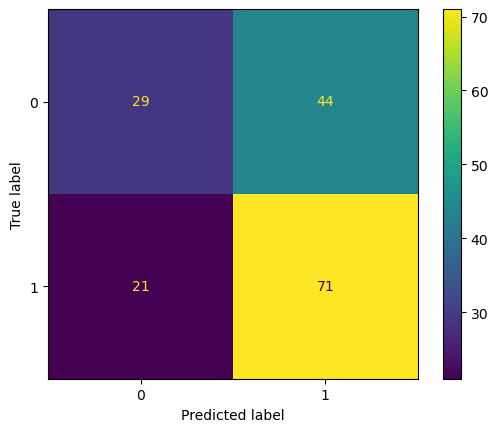

In [40]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=model_l1.classes_)
disp.plot()
plt.savefig('l1_cm', dpi=300)

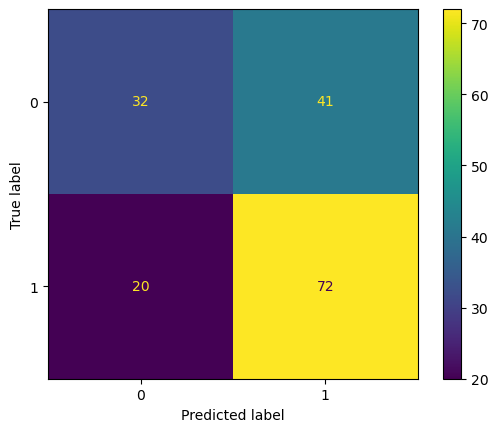

In [41]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_l2,display_labels=model_l2.classes_)
disp.plot()
plt.savefig('l2_cm', dpi=300)

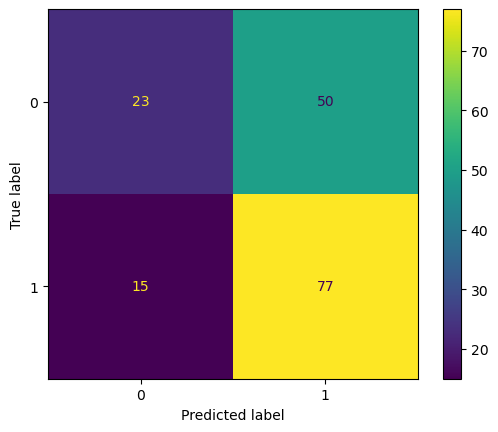

In [42]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_elasticnet,display_labels=model_elasticnet.classes_)
disp.plot()
plt.savefig('elasticnet_test', dpi=300)

In [43]:
from sklearn.metrics import classification_report

In [44]:
y_pred = model_l1.predict(test_features)
cr = classification_report(test_target, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.58      0.40      0.47        73
           1       0.62      0.77      0.69        92

    accuracy                           0.61       165
   macro avg       0.60      0.58      0.58       165
weighted avg       0.60      0.61      0.59       165



In [45]:
y_pred = model_l2.predict(test_features)
cr = classification_report(test_target, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.62      0.44      0.51        73
           1       0.64      0.78      0.70        92

    accuracy                           0.63       165
   macro avg       0.63      0.61      0.61       165
weighted avg       0.63      0.63      0.62       165



In [46]:
y_pred = model_elasticnet.predict(test_features)
cr = classification_report(test_target, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.61      0.32      0.41        73
           1       0.61      0.84      0.70        92

    accuracy                           0.61       165
   macro avg       0.61      0.58      0.56       165
weighted avg       0.61      0.61      0.58       165



LR+shap

In [25]:
import shap
shap.initjs() 

In [26]:
explainer_l1 = shap.LinearExplainer(model_l1, test_features, feature_perturbation="interventional")
explainer_l2=shap.LinearExplainer(model_l2, test_features, feature_perturbation="interventional")
explainer_elasticnet=shap.LinearExplainer(model_elasticnet, test_features, feature_perturbation="interventional")

The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, or maskers.Impute)


In [27]:
shap_values_l1=explainer_l1(test_features)
shap_values_l2=explainer_l2(test_features)
shap_values_elasticnet=explainer_elasticnet(test_features)

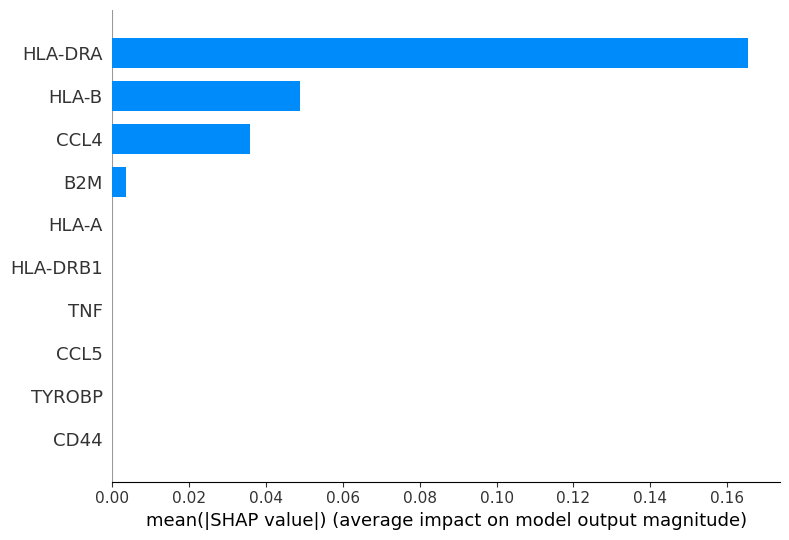

In [29]:
shap.summary_plot(shap_values_l1, test_features, plot_type="bar")

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


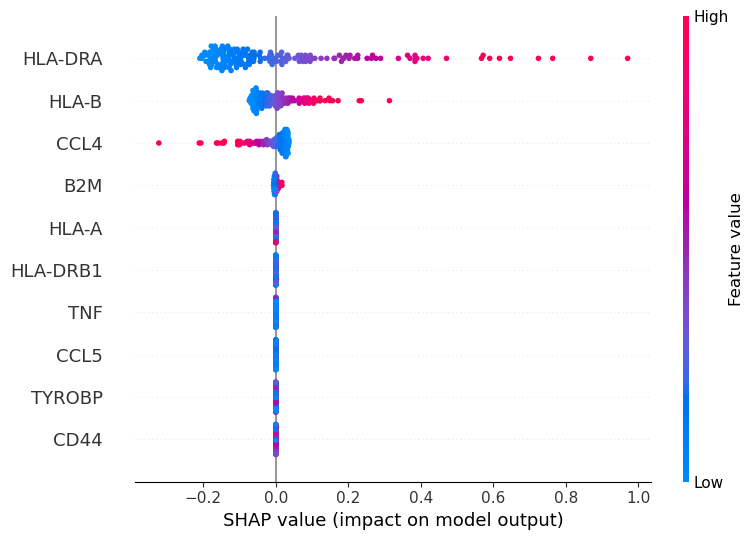

In [28]:
shap.summary_plot(shap_values_l1, test_features)

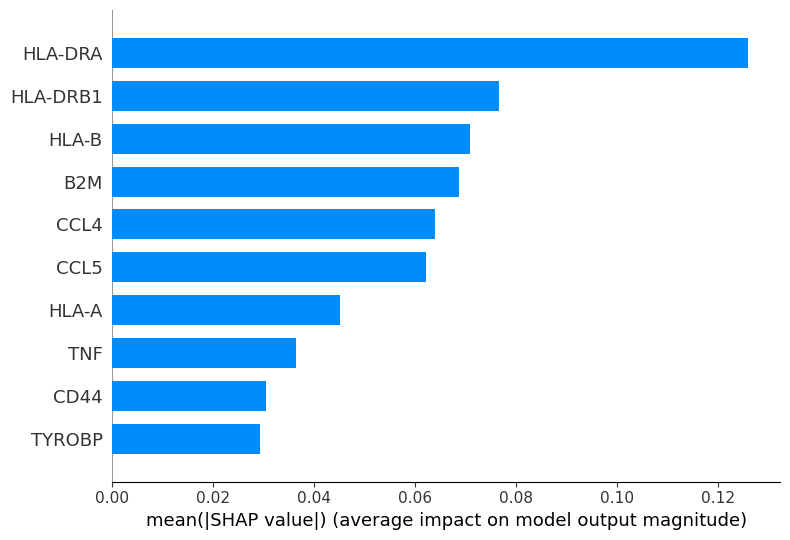

In [31]:
shap.summary_plot(shap_values_l2, test_features, plot_type="bar")

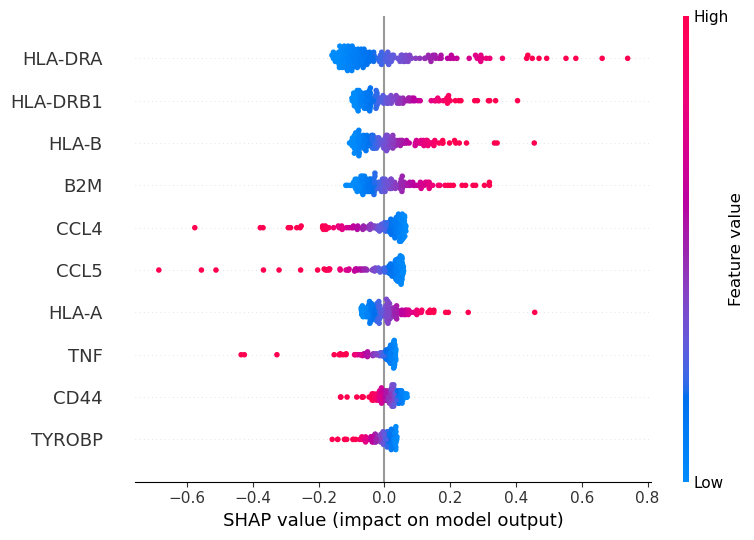

In [30]:
shap.summary_plot(shap_values_l2, test_features)

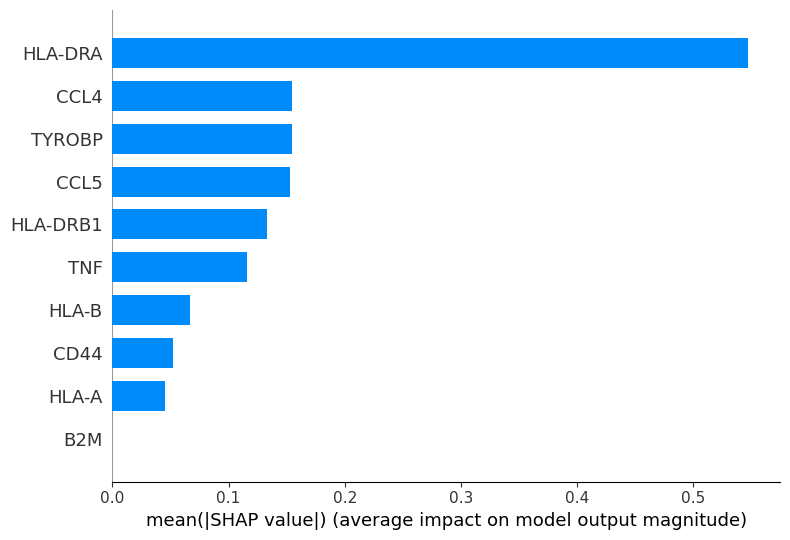

In [32]:
shap.summary_plot(shap_values_elasticnet, test_features, plot_type="bar")

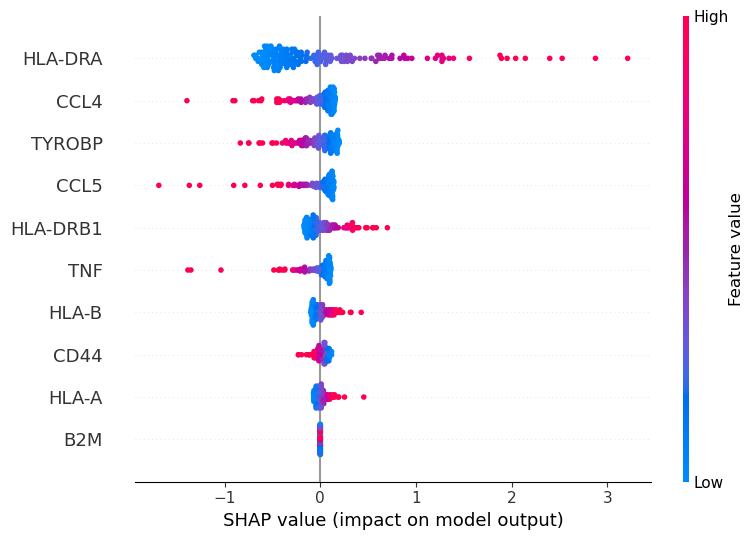

In [33]:
shap.summary_plot(shap_values_elasticnet, test_features)

SVC #grid search无法正常running

In [34]:
from sklearn.svm import SVC

In [35]:
svc_linear = SVC(kernel='linear')
svc_rbf=SVC(kernel='rbf')
svc_sigmoid=SVC(kernel='sigmoid')

In [36]:
model_svc_linear=svc_linear.fit(train_features, train_target)
model_svc_rbf=svc_rbf.fit(train_features, train_target)
model_svc_sigmoid=svc_sigmoid.fit(train_features,train_target)

SVC+effect

In [50]:
predictions_svc_linear = model_svc_linear.predict(test_features)
predictions_svc_rbf=model_svc_rbf.predict(test_features)
predictions_svc_sigmoid=model_svc_sigmoid.predict(test_features)

In [51]:
cm_svc_linear = confusion_matrix(test_target, predictions_svc_linear, labels=model_svc_linear.classes_)
cm_svc_rbf=confusion_matrix(test_target, predictions_svc_rbf, labels=model_svc_rbf.classes_)
cm_svc_sigmoid=confusion_matrix(test_target, predictions_svc_sigmoid, labels=model_svc_sigmoid.classes_)

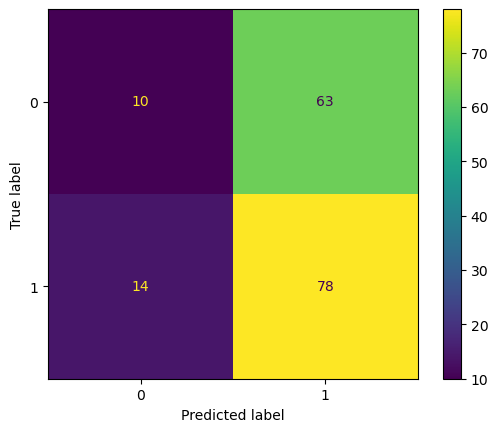

In [52]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svc_linear,display_labels=model_svc_linear.classes_)
disp.plot()
plt.savefig('svc_linear_cm', dpi=300)

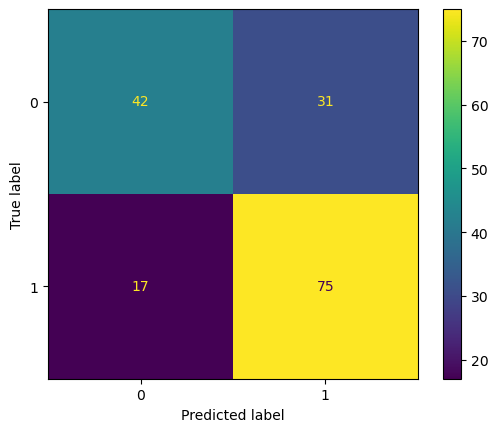

In [53]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svc_rbf,display_labels=model_svc_rbf.classes_)
disp.plot()
plt.savefig('svc_rbf_cm', dpi=300)

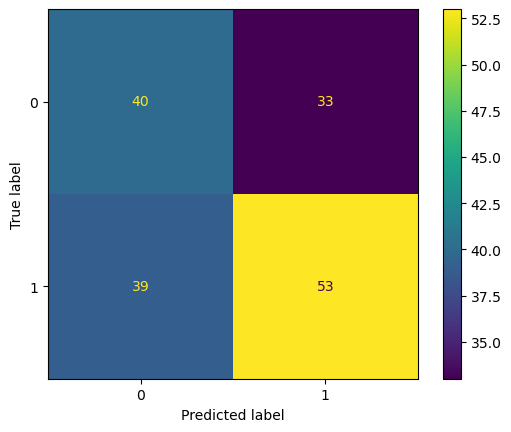

In [54]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svc_sigmoid,display_labels=model_svc_sigmoid.classes_)
disp.plot()
plt.savefig('svc_sigmoid_cm', dpi=300)

In [55]:
y_pred = model_svc_linear.predict(test_features)
cr = classification_report(test_target, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.42      0.14      0.21        73
           1       0.55      0.85      0.67        92

    accuracy                           0.53       165
   macro avg       0.48      0.49      0.44       165
weighted avg       0.49      0.53      0.46       165



In [56]:
y_pred = model_svc_rbf.predict(test_features)
cr = classification_report(test_target, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.71      0.58      0.64        73
           1       0.71      0.82      0.76        92

    accuracy                           0.71       165
   macro avg       0.71      0.70      0.70       165
weighted avg       0.71      0.71      0.70       165



In [57]:
y_pred = model_svc_sigmoid.predict(test_features)
cr = classification_report(test_target, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.51      0.55      0.53        73
           1       0.62      0.58      0.60        92

    accuracy                           0.56       165
   macro avg       0.56      0.56      0.56       165
weighted avg       0.57      0.56      0.56       165



SVC+shap

In [37]:
explainer_svc_linear = shap.LinearExplainer(model_svc_linear, test_features, feature_perturbation="interventional")

The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, or maskers.Impute)


In [38]:
shap_values_svc_linear=explainer_svc_linear(test_features)

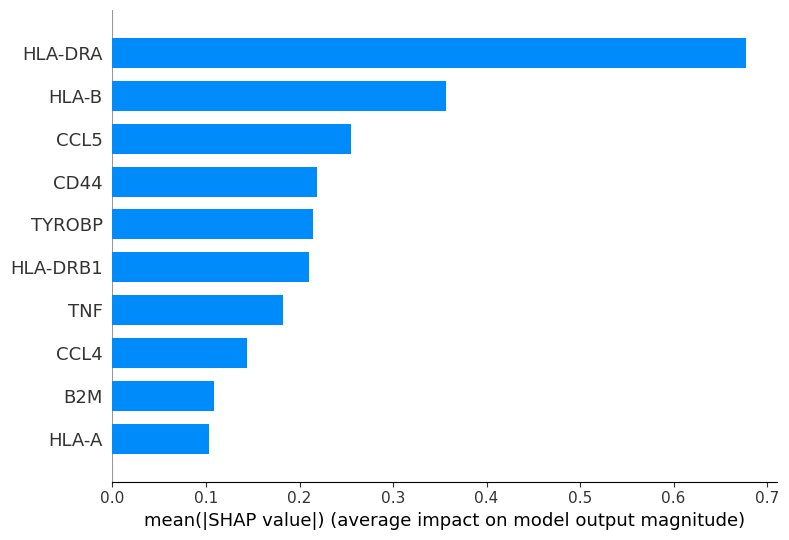

In [39]:
shap.summary_plot(shap_values_svc_linear, test_features, plot_type="bar")

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


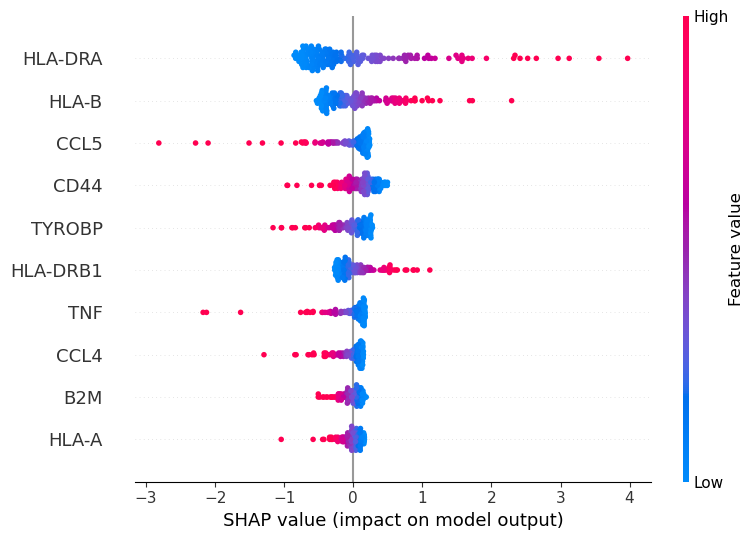

In [40]:
shap.summary_plot(shap_values_svc_linear, test_features)

Rf+grid search

In [41]:
train_features, test_features, train_target, test_target = train_test_split(
    features, target, 
    test_size = 0.3)

In [42]:
from sklearn.ensemble import RandomForestClassifier

In [43]:
rfc_clf = RandomForestClassifier(oob_score=True)

In [43]:
param_distributions={'criterion':['gini','entropy'],'min_samples_split':[2,20,50,100,200]}

In [44]:
random_search =RandomizedSearchCV(rfc_clf, param_distributions, cv=10)

In [45]:
random_search.fit(train_features, train_target)

RandomizedSearchCV(cv=10, estimator=RandomForestClassifier(oob_score=True),
                   param_distributions={'criterion': ['gini', 'entropy'],
                                        'min_samples_split': [2, 20, 50, 100,
                                                              200]})

In [46]:
random_search.best_params_

{'min_samples_split': 50, 'criterion': 'entropy'}

In [44]:
rfc_clf = RandomForestClassifier(oob_score=True,min_samples_split=50,criterion='entropy')

In [45]:
model_rfc=rfc_clf.fit(train_features, train_target)

Rf+effect

In [68]:
predictions_rfc = model_rfc.predict(test_features)

In [69]:
cm_rfc = confusion_matrix(test_target, predictions_rfc, labels=model_rfc.classes_)

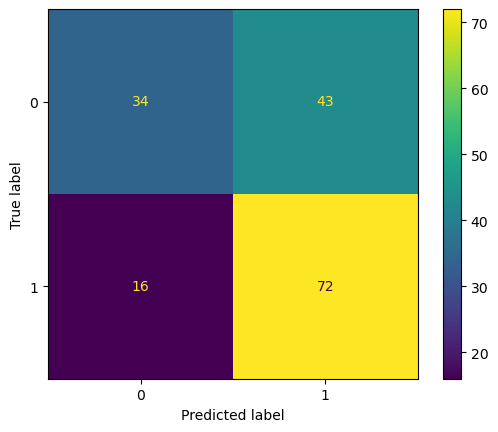

In [70]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rfc,display_labels=model_rfc.classes_)
disp.plot()
plt.savefig('rfc_cm', dpi=300)

In [71]:
y_pred = model_rfc.predict(test_features)
cr = classification_report(test_target, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.68      0.44      0.54        77
           1       0.63      0.82      0.71        88

    accuracy                           0.64       165
   macro avg       0.65      0.63      0.62       165
weighted avg       0.65      0.64      0.63       165



RF+shap

In [46]:
explainer = shap.TreeExplainer(rfc_clf)
shap_values = explainer(test_features)
shap_values_data=explainer.shap_values(test_features)

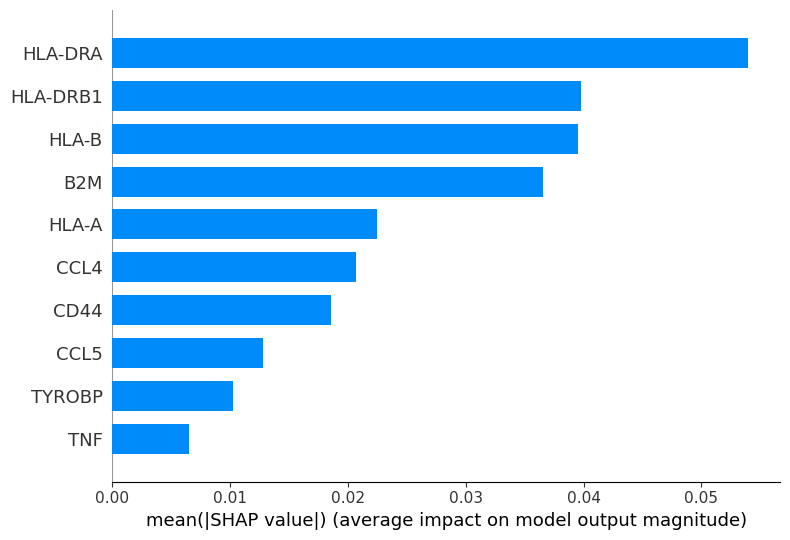

In [47]:
shap.summary_plot(shap_values_data[1], test_features, plot_type="bar")

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


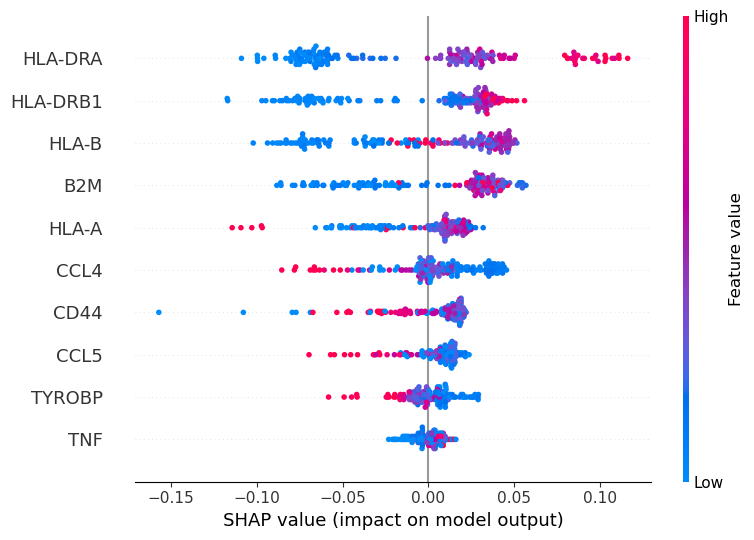

In [48]:
shap.summary_plot(shap_values_data[1], test_features)

Extra tree+grid search

In [49]:
from sklearn.ensemble import ExtraTreesClassifier

In [50]:
et_clf = ExtraTreesClassifier()

In [51]:
param_distributions={'criterion':['gini','entropy'],'min_samples_split':[2,20,50,100,200]}

In [52]:
random_search =RandomizedSearchCV(et_clf, param_distributions, cv=10)

In [53]:
random_search.fit(train_features, train_target)

RandomizedSearchCV(cv=10, estimator=ExtraTreesClassifier(),
                   param_distributions={'criterion': ['gini', 'entropy'],
                                        'min_samples_split': [2, 20, 50, 100,
                                                              200]})

In [54]:
random_search.best_params_

{'min_samples_split': 50, 'criterion': 'entropy'}

In [51]:
et_clf = ExtraTreesClassifier(min_samples_split=50,criterion='entropy')

In [52]:
model_et=et_clf.fit(train_features, train_target)

extra tree+effect

In [80]:
predictions_et = model_et.predict(test_features)

In [81]:
cm_et = confusion_matrix(test_target, predictions_et, labels=model_et.classes_)

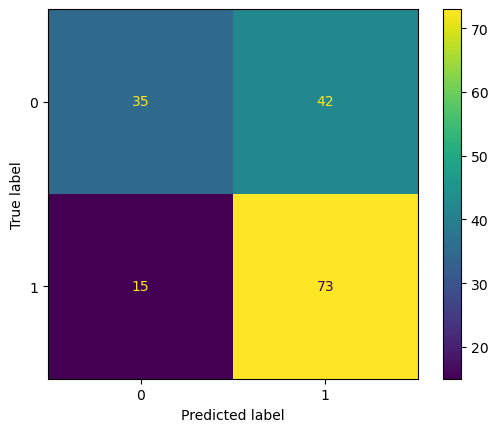

In [82]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_et,display_labels=model_et.classes_)
disp.plot()
plt.savefig('et_cm', dpi=300)

In [83]:
y_pred = model_et.predict(test_features)
cr = classification_report(test_target, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.70      0.45      0.55        77
           1       0.63      0.83      0.72        88

    accuracy                           0.65       165
   macro avg       0.67      0.64      0.64       165
weighted avg       0.67      0.65      0.64       165



extra tree+shap

In [53]:
explainer = shap.TreeExplainer(et_clf)
shap_values = explainer(test_features)

In [54]:
shap_values_data=explainer.shap_values(test_features)

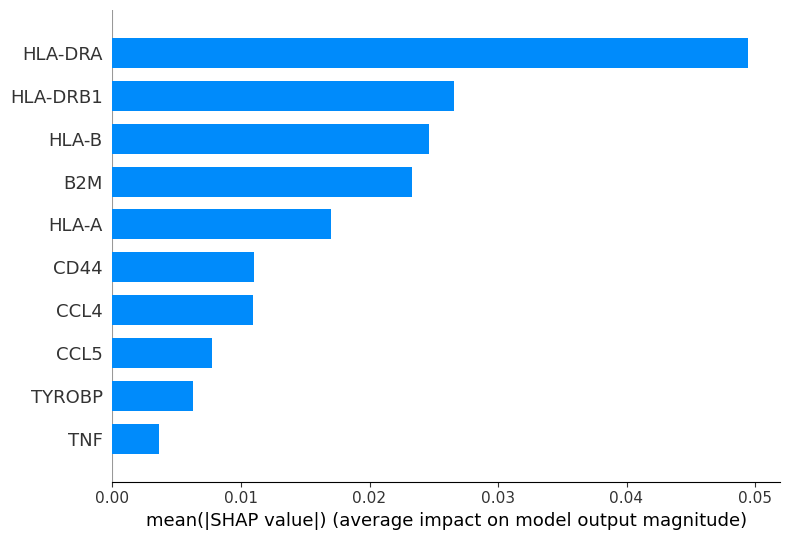

In [55]:
shap.summary_plot(shap_values_data[1], test_features, plot_type="bar")

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


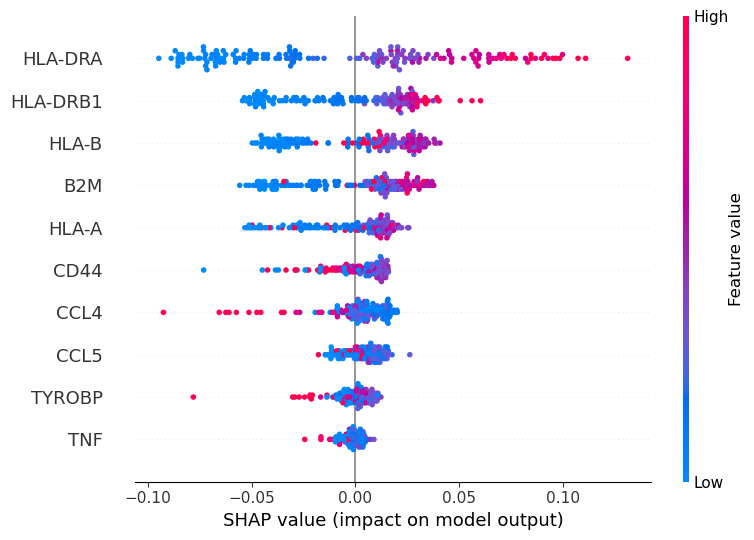

In [56]:
shap.summary_plot(shap_values_data[1], test_features)

xgboost+grid search

In [57]:
import xgboost

In [58]:
xgb_clf = xgboost.XGBClassifier()

In [59]:
param_distributions={'learning_rate':[0.01,0.05,0.1,0.15,0.2,0.25,0.3,0.5,0.7,1.0],'gamma':[0,1,10,20,50,100,200],'max_depth':[3,4,5,6,7,8,9,10],'min_child_weight':[0,1,10,20,50,100,200],'subsample':[0.1,0.3,0.5,0.7,1.0]}

In [60]:
random_search =RandomizedSearchCV(xgb_clf, param_distributions, cv=10)

In [61]:
random_search.fit(train_features, train_target)

RandomizedSearchCV(cv=10,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric=None, feature_types=None,
                                           gamma=None, gpu_id=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constraints=None,
                                           learning_rat...
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           n_estimators=100, n_jobs=None,
                                           num_parallel_tree=None,
                                           predictor=None, random_state=None, ...),
                   param_distributions={'gamma': [0, 1, 10, 20, 50, 100, 200],
                                        'learning_rate': [0.01, 0.05, 0.1, 0.15,
                                                          0.2, 0.25, 0.3, 0.5,
                                                          0.7, 1.0],
                                        'max_depth': [3, 4, 5, 6, 7, 8, 9, 10],
                                        'min_child_weight': [0, 1, 10, 20, 50,
                                                             100, 200],
                                        'subsample': [0.1, 0.3, 0.5, 0.7, 1.0]})

In [62]:
random_search.best_params_

{'subsample': 0.7,
 'min_child_weight': 0,
 'max_depth': 4,
 'learning_rate': 0.05,
 'gamma': 10}

In [59]:
xgb_clf = xgboost.XGBClassifier(subsample=0.7,min_child_weight=0,max_depth=4,learning_rate=0.05,gamma=10)

In [60]:
model_xgb=xgb_clf.fit(train_features, train_target)

xgboost+effect

In [76]:
predictions_xgb = model_xgb.predict(test_features)

In [77]:
cm_xgb = confusion_matrix(test_target, predictions_xgb, labels=model_xgb.classes_)

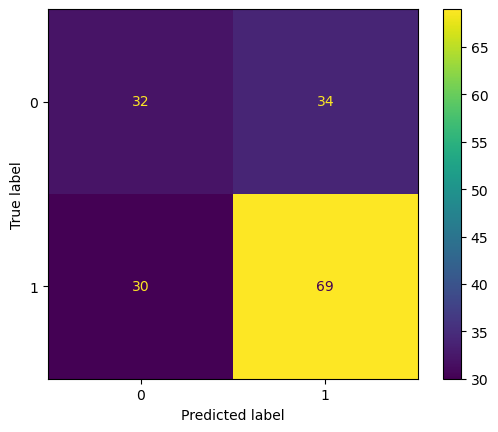

In [78]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_xgb,display_labels=model_xgb.classes_)
disp.plot()
plt.savefig('xgb_cm', dpi=300)

In [95]:
y_pred = model_xgb.predict(test_features)
cr = classification_report(test_target, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        77
           1       0.53      1.00      0.70        88

    accuracy                           0.53       165
   macro avg       0.27      0.50      0.35       165
weighted avg       0.28      0.53      0.37       165



D:\ANACONDA\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
D:\ANACONDA\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
D:\ANACONDA\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


xgboost+shap

In [61]:
explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer(test_features)
shap_values_data=explainer.shap_values(test_features)

ntree_limit is deprecated, use `iteration_range` or model slicing instead.


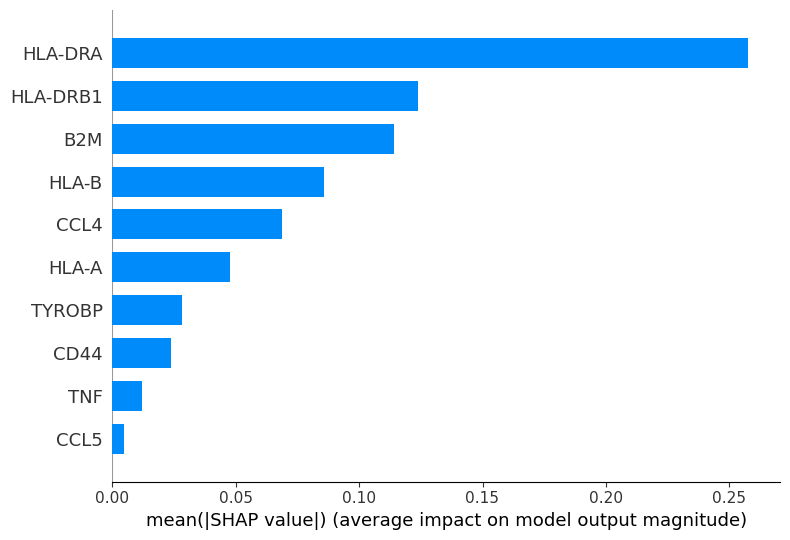

In [62]:
shap.summary_plot(shap_values_data, test_features, plot_type="bar")

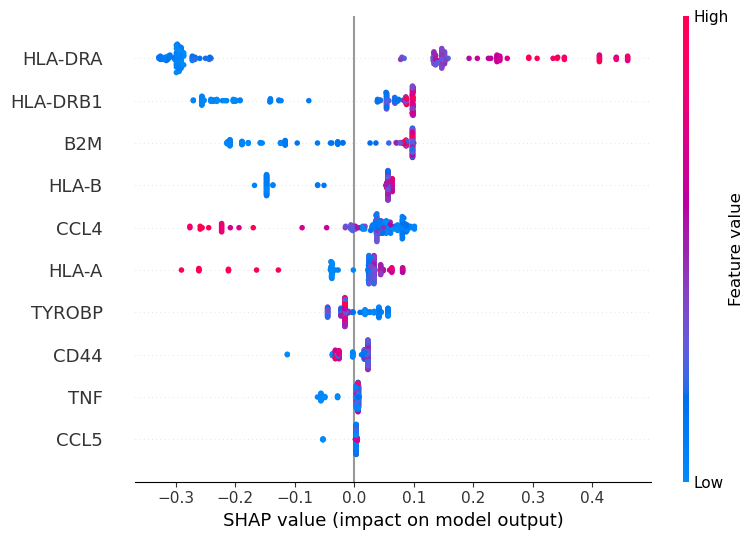

In [63]:
shap.summary_plot(shap_values_data, test_features)

LGBM+grid search

In [64]:
from lightgbm.sklearn import LGBMClassifier

In [65]:
LGBM = LGBMClassifier()

In [67]:
param_distributions={'boosting_type':['gbdt','dart','rf'],'learning_rate':[0.01,0.05,0.1,0.15,0.2,0.25,0.3,0.5,0.7,1.0],'reg_alpha':[0,1,10,20,50,100],'reg_lambda':[0,1,10,20,50,100],'max_depth':[3,4,5,6,7,8],'min_split_gain':[0,1,5,10,15,20],'subsample':[0.1,0.3,0.5,0.7,1.0]}

In [68]:
random_search =RandomizedSearchCV(xgb_clf, param_distributions, cv=10)

In [69]:
random_search.fit(train_features, train_target)

[22:34:34] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:34] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:34] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:34] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:34] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\

[22:34:35] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:35] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:35] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:35] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:35] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\

[22:34:36] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:36] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:36] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:37] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\xgboost-ci-windows\src\learner.cc:767: 
Parameters: { "boosting_type", "min_split_gain" } are not used.

[22:34:37] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-07593ffd91cd9da33-1\xgboost\

RandomizedSearchCV(cv=10,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric=None, feature_types=None,
                                           gamma=10, gpu_id=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constraints=None,
                                           learning_rate=...
                                           n_estimators=100, n_jobs=None,
                                           num_parallel_tree=None,
                                           predictor=None, random_state=None, ...),
                   param_distributions={'boosting_type': ['gbdt', 'dart', 'rf'],
                                        'learning_rate': [0.01, 0.05, 0.1, 0.15,
                                                          0.2, 0.25, 0.3, 0.5,
                                                          0.7, 1.0],
                                        'max_depth': [3, 4, 5, 6, 7, 8],
                                        'min_split_gain': [0, 1, 5, 10, 15, 20],
                                        'reg_alpha': [0, 1, 10, 20, 50, 100],
                                        'reg_lambda': [0, 1, 10, 20, 50, 100],
                                        'subsample': [0.1, 0.3, 0.5, 0.7, 1.0]})

In [70]:
random_search.best_params_

{'subsample': 0.7,
 'reg_lambda': 1,
 'reg_alpha': 20,
 'min_split_gain': 15,
 'max_depth': 8,
 'learning_rate': 0.3,
 'boosting_type': 'gbdt'}

In [66]:
LGBM = LGBMClassifier(subsample=0.7,reg_lambda=1,reg_alpha=20,min_split_gain=15,max_depth=8,learning_rate=0.3,boosting_type='gbdt')

In [67]:
model_LGBM=LGBM.fit(train_features, train_target)

[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Info] Number of positive: 217, number of negative: 165
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000926 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1280
[LightGBM] [Info] Number of data points in the train set: 382, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.568063 -> initscore=0.273952
[LightGBM] [Info] Start training from score 0.273952
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] 

Could not find the number of physical cores for the following reason:
'utf-8' codec can't decode byte 0xba in position 24: invalid start byte
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  File "D:\ANACONDA\lib\site-packages\joblib\externals\loky\backend\context.py", line 230, in _count_physical_cores
    cpu_info = cpu_info.stdout.decode('utf-8').splitlines()


LGBM+effect

In [71]:
predictions_LGBM = model_LGBM.predict(test_features)

[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).


In [74]:
cm_LGBM = confusion_matrix(test_target, predictions_LGBM, labels=model_LGBM.classes_)

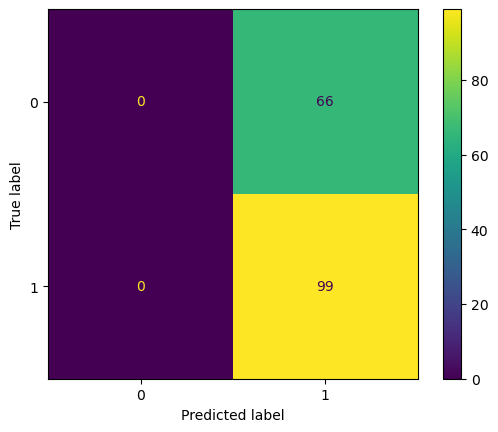

In [75]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_LGBM,display_labels=model_LGBM.classes_)
disp.plot()
plt.savefig('LGBM_cm', dpi=300)

In [107]:
y_pred = model_LGBM.predict(test_features)
cr = classification_report(test_target, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        77
           1       0.53      1.00      0.70        88

    accuracy                           0.53       165
   macro avg       0.27      0.50      0.35       165
weighted avg       0.28      0.53      0.37       165



D:\ANACONDA\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
D:\ANACONDA\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
D:\ANACONDA\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


LGBM+shap

In [68]:
explainer = shap.TreeExplainer(LGBM)
shap_values = explainer(test_features)
shap_values_data=explainer.shap_values(test_features)

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray


In [70]:
shap_values_data

[array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]])]

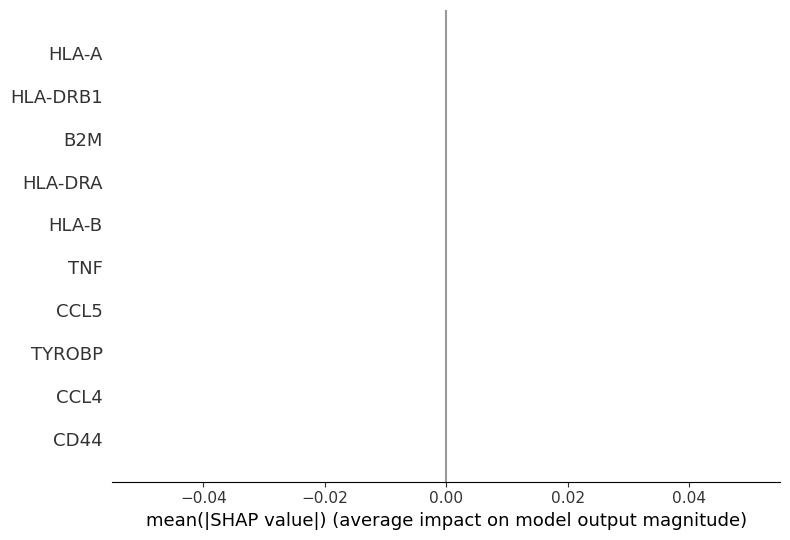

In [69]:
shap.summary_plot(shap_values_data[1], test_features, plot_type="bar")

No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


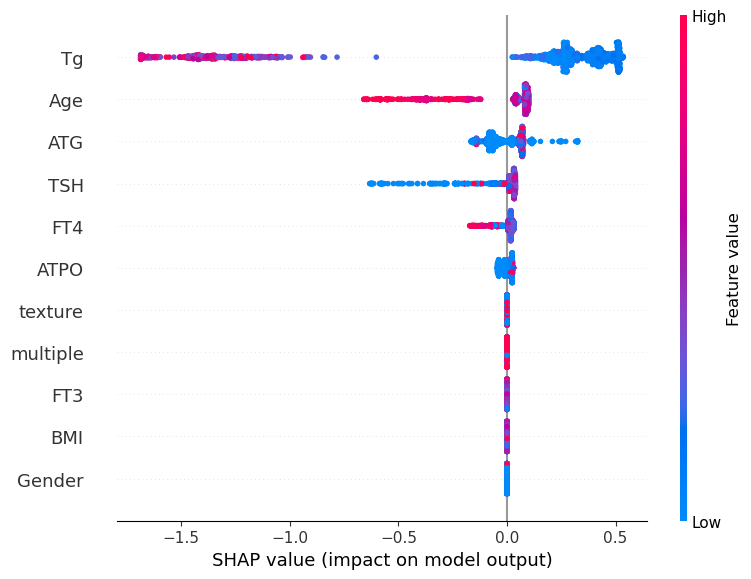

In [226]:
shap.summary_plot(shap_values_data[1], test_features)

ROC curve+PR curve

In [79]:
from sklearn.metrics import (precision_recall_curve,PrecisionRecallDisplay)

In [109]:
train_features_str, test_features_str, train_target_str, test_target_str = train_test_split(
    features_str, target, 
    test_size = 0.3)

In [110]:
train_features, test_features, train_target, test_target = train_test_split(
    features, target, 
    test_size = 0.3)

D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


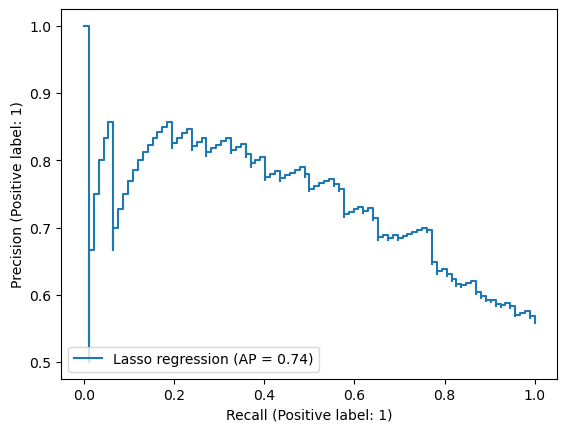

In [111]:
display = PrecisionRecallDisplay.from_estimator(
    model_l1, test_features_str, test_target_str, name="Lasso regression"
)

D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


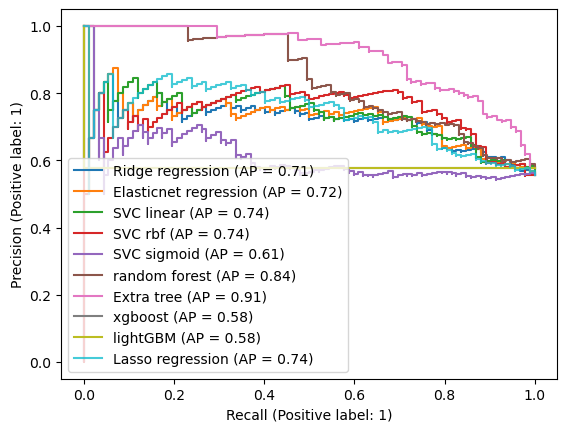

In [112]:
ax = plt.gca()
display2 = PrecisionRecallDisplay.from_estimator(
    model_l2, test_features_str, test_target_str, ax=ax,name="Ridge regression")
display3 = PrecisionRecallDisplay.from_estimator(
    model_elasticnet, test_features_str, test_target_str,ax=ax,name="Elasticnet regression")
display4 = PrecisionRecallDisplay.from_estimator(
    model_svc_linear, test_features_str, test_target_str,ax=ax,name="SVC linear")
display5 = PrecisionRecallDisplay.from_estimator(
    model_svc_rbf, test_features_str, test_target_str,ax=ax,name="SVC rbf")
display6 = PrecisionRecallDisplay.from_estimator(
    model_svc_sigmoid, test_features_str, test_target_str,ax=ax,name="SVC sigmoid")
display7=PrecisionRecallDisplay.from_estimator(
    model_rfc, test_features, test_target,ax=ax,name="random forest")
display8=PrecisionRecallDisplay.from_estimator(
    model_et, test_features, test_target,ax=ax,name="Extra tree")
display9=PrecisionRecallDisplay.from_estimator(
    model_xgb, test_features, test_target,ax=ax,name="xgboost")
display10=PrecisionRecallDisplay.from_estimator(
    model_LGBM, test_features, test_target,ax=ax,name="lightGBM")
display.plot(ax=ax, alpha=0.8)
plt.savefig('PR_curve', dpi=300)

In [113]:
from sklearn.metrics import RocCurveDisplay

D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\base.py:420: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


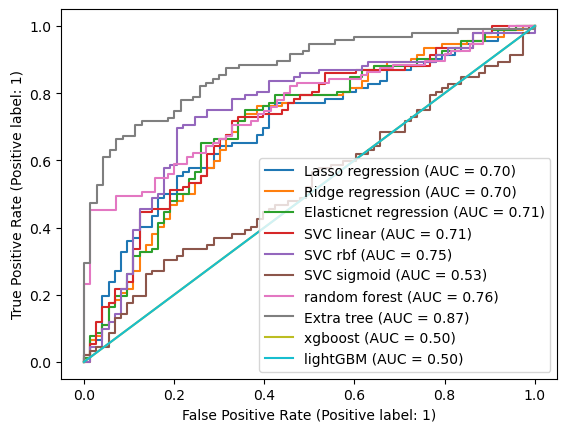

In [114]:
ax2 = plt.gca()
display1=RocCurveDisplay.from_estimator(
    model_l1, test_features_str, test_target_str, ax=ax2,name="Lasso regression")
display2 = RocCurveDisplay.from_estimator(
    model_l2, test_features_str, test_target_str, ax=ax2,name="Ridge regression")
display3 = RocCurveDisplay.from_estimator(
    model_elasticnet, test_features_str, test_target_str,ax=ax2,name="Elasticnet regression")
display4 = RocCurveDisplay.from_estimator(
    model_svc_linear, test_features_str, test_target_str,ax=ax2,name="SVC linear")
display5 = RocCurveDisplay.from_estimator(
    model_svc_rbf, test_features_str, test_target_str,ax=ax2,name="SVC rbf")
display6 = RocCurveDisplay.from_estimator(
    model_svc_sigmoid, test_features_str, test_target_str,ax=ax2,name="SVC sigmoid")
display7=RocCurveDisplay.from_estimator(
    model_rfc, test_features, test_target,ax=ax2,name="random forest")
display8=RocCurveDisplay.from_estimator(
    model_et, test_features, test_target,ax=ax2,name="Extra tree")
display9=RocCurveDisplay.from_estimator(
    model_xgb, test_features, test_target,ax=ax2,name="xgboost")
display10=RocCurveDisplay.from_estimator(
    model_LGBM, test_features, test_target,ax=ax2,name="lightGBM")
plt.savefig('Roc_curve', dpi=300)

集成学习模型构建

In [73]:
from sklearn.ensemble import StackingClassifier

In [74]:
log_ensemble = LogisticRegression()

In [75]:
stk_clf_linear = StackingClassifier(
      estimators=[('l1', log_l1), ('l2', log_l2), ('elasticnet', log_elasticnet),('svc_linear',svc_linear),('svc_rbf',svc_rbf),('svc_sigmoid',svc_sigmoid)],
    final_estimator=log_ensemble)

In [77]:
train_features_str, test_features_str, train_target_str, test_target_str = train_test_split(
    features_str, target, 
    test_size = 0.3)

In [78]:
model_linear=stk_clf_linear.fit(train_features_str,train_target_str)

D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
D:\ANACONDA\lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [119]:
stk_linear_proba=stk_clf_linear.predict_proba(features_str)

In [120]:
stk_linear_proba=pd.DataFrame(stk_linear_proba)

In [121]:
stk_linear_proba.to_excel("./stk_linear_proba.xlsx")

In [79]:
stk_clf_tree = StackingClassifier(
      estimators=[('rfc',rfc_clf),('et',et_clf),('xgb',xgb_clf),('LGBM',LGBM)],
    final_estimator=log_ensemble)

In [80]:
model_tree=stk_clf_tree.fit(train_features,train_target)

[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Info] Number of positive: 224, number of negative: 158
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000073 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1280
[LightGBM] [Info] Number of data points in the train set: 382, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.586387 -> initscore=0.349051
[LightGBM] [Info] Start training from score 0.349051
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Warning] Accuracy may be bad since you didn't explicitly set num_leaves OR 2^max_depth > num_leaves. (num_leaves=31).
[LightGBM] [Info] Number of positive: 179, number of negative: 126
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000102 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1020
[LightGBM] [Info] Number of data points in the train set: 305, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.586885 -> initscore=0.351104
[LightGBM] [Info] Start training from score 0.351104
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


In [81]:
import joblib

In [83]:
joblib.dump(model_tree, 'model.pkl')

['model.pkl']

In [124]:
stk_clf_tree_proba=stk_clf_tree.predict_proba(features)

In [125]:
stk_clf_tree_proba=pd.DataFrame(stk_clf_tree_proba)

In [126]:
stk_clf_tree_proba.to_excel("./stk_tree_proba.xlsx")

In [127]:
data2 = pd.read_excel("ensmble_learning_proba3.xlsx",index_col=0,sheet_name=0)
data2

,tree_proba,linear_proba,pathology
0,0.722089,0.784805,1
1,0.356918,0.395751,0
2,0.338320,0.325506,0
3,0.397306,0.409151,0
4,0.655368,0.793168,0
...,...,...,...
542,0.480481,0.444144,0
543,0.762523,0.765040,1
544,0.525987,0.550576,0
545,0.623808,0.617020,1


In [128]:
features2 = data2[['tree_proba','linear_proba']]
target2 = data2.pathology

In [129]:
train_features2, test_features2, train_target2, test_target2 = train_test_split(
    features2, target2, 
    test_size = 0.3)

In [130]:
log_ensemble = LogisticRegression()

In [131]:
model_ensemble=log_ensemble.fit(train_features2,train_target2)

集成学习模型效能

In [132]:
predictions_linear = model_linear.predict(test_features_str)
predictions_tree=model_tree.predict(test_features)
predictions_ensemble=model_ensemble.predict(test_features2)

In [133]:
cm_linear = confusion_matrix(test_target_str, predictions_linear, labels=model_linear.classes_)
cm_tree=confusion_matrix(test_target, predictions_tree, labels=model_tree.classes_)
cm_ensemble=confusion_matrix(test_target2, predictions_ensemble, labels=model_ensemble.classes_)

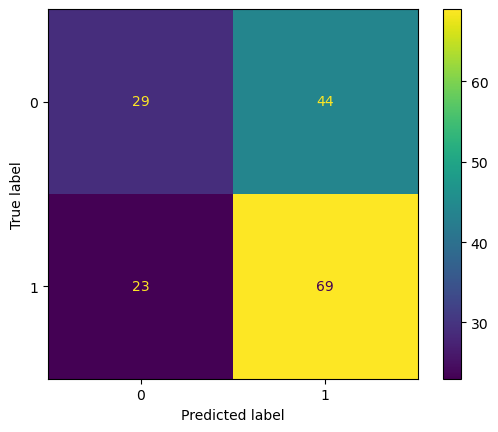

In [134]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_linear,display_labels=model_linear.classes_)
disp.plot()
plt.savefig('linear_cm', dpi=300)

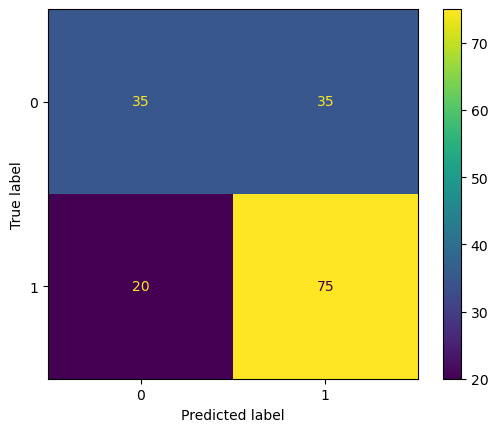

In [135]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_tree,display_labels=model_tree.classes_)
disp.plot()
plt.savefig('tree_cm', dpi=300)

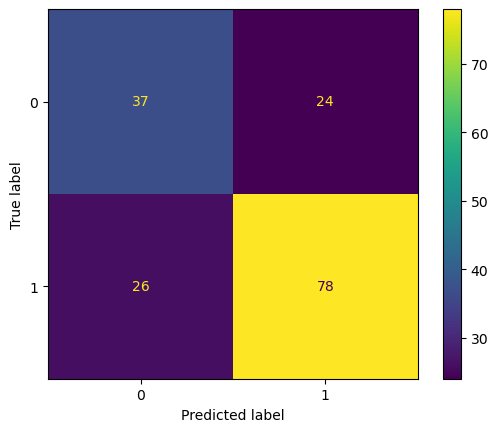

In [136]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm_ensemble,display_labels=model_ensemble.classes_)
disp.plot()
plt.savefig('ensemble_cm', dpi=300)

In [137]:
y_pred = model_linear.predict(test_features_str)
cr = classification_report(test_target_str, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.56      0.40      0.46        73
           1       0.61      0.75      0.67        92

    accuracy                           0.59       165
   macro avg       0.58      0.57      0.57       165
weighted avg       0.59      0.59      0.58       165



In [138]:
y_pred = model_tree.predict(test_features)
cr = classification_report(test_target, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.64      0.50      0.56        70
           1       0.68      0.79      0.73        95

    accuracy                           0.67       165
   macro avg       0.66      0.64      0.65       165
weighted avg       0.66      0.67      0.66       165



In [139]:
y_pred = model_ensemble.predict(test_features2)
cr = classification_report(test_target2, y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.59      0.61      0.60        61
           1       0.76      0.75      0.76       104

    accuracy                           0.70       165
   macro avg       0.68      0.68      0.68       165
weighted avg       0.70      0.70      0.70       165



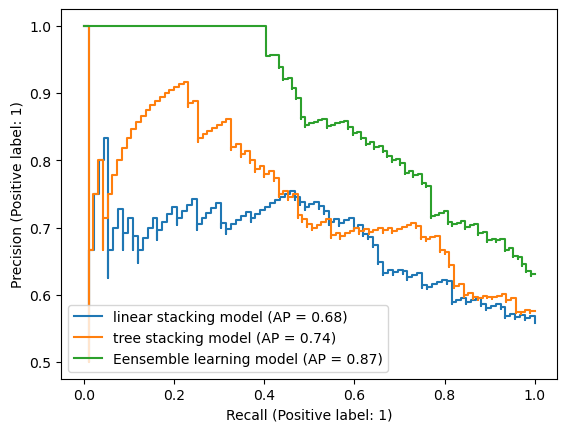

In [140]:
ax = plt.gca()
display2 = PrecisionRecallDisplay.from_estimator(
    model_linear, test_features_str, test_target_str, ax=ax,name="linear stacking model")
display3 = PrecisionRecallDisplay.from_estimator(
    model_tree, test_features, test_target,ax=ax,name="tree stacking model")
display4 = PrecisionRecallDisplay.from_estimator(
    model_ensemble, test_features2, test_target2,ax=ax,name="Eensemble learning model")
plt.savefig('PR_curve_ensemble', dpi=300)

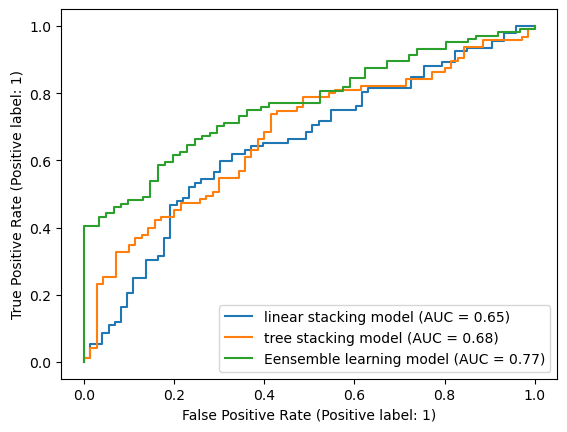

In [141]:
ax = plt.gca()
display2 = RocCurveDisplay.from_estimator(
    model_linear, test_features_str, test_target_str, ax=ax,name="linear stacking model")
display3 = RocCurveDisplay.from_estimator(
    model_tree, test_features, test_target,ax=ax,name="tree stacking model")
display4 = RocCurveDisplay.from_estimator(
    model_ensemble, test_features2, test_target2,ax=ax,name="Eensemble learning model")
plt.savefig('Roc_curve_ensemble', dpi=300)